# 報告圖片與實驗（依文章順序）

| 順序 | 論文項目 | 原 notebook 儲存格 |
|---|---|---|
| 2 | §3 表2：資料統計與完整日數 | 5 |
| 3 | §3 圖1(a–c)：歷史特徵分析 | 9、11–13 |
| 4 | §4：冬季平日尖峰用電占比 | 7 |
| 6 | §5：特徵與模型定義 | 15、17 |
| 7 | §6：時間切分、指標與決策門檻 | 17、31、32 |
| 8 | §6 表3：預測方法比較 | 19 |
| 9 | §7.1：11:00 與午夜比較 | 25 |
| 10 | §7.1：逐 fold 與 bootstrap | 27 |
| 11 | §7.1 表4：特徵消融 | 23 |
| 12 | §7.2 表5：決策收益與動作次數 | 31 |
| 13 | §7.3：Water/AC 預熱 | 34 |
| 14 | §8.1 表6：OLS、CI、p、VIF | 29 |
| 15 | §8.2：三個錯誤案例 | 36 |


## 0. 共用設定

載入套件與資料路徑，將新輸出放入獨立目錄。

In [1]:
import time, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dateutil.easter import easter

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRAY = "#8a8a85"
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=[C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN]),
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10})

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data" / "household_power_consumption.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("請從專案目錄開啟 notebook；需要 data/household_power_consumption.zip")
DATA_ZIP = ROOT / "data" / "household_power_consumption.zip"
EXT = ROOT / "data" / "external"
RESULTS = ROOT / "results" / "paper_ordered"
FIGURES = ROOT / "figures" / "paper_ordered"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
def save(df, name):
    df.to_csv(RESULTS / f"{name}.csv")
    return df

# Tempo 電價（EDF，2026-08-01 起，TTC €/kWh）
PRICE = {"blue_HC": .1356, "blue_HP": .1654, "white_HC": .1536, "white_HP": .1921, "red_HC": .1615, "red_HP": .7295}
SAVE_PER_KWH = PRICE["red_HP"] - PRICE["red_HC"]
RED_DAYS_PER_YEAR = 22
print("shift saving on a red day:", round(SAVE_PER_KWH, 4), "€/kWh")

shift saving on a red day: 0.568 €/kWh


## 2. §3／表2：資料與目標統計

重建每日用電，輸出完整日數及四分路的平均、標準差與範圍。

In [3]:
t0 = time.time()
with zipfile.ZipFile(DATA_ZIP) as z:
    name = [n for n in z.namelist() if n.endswith(".txt")][0]
    raw = pd.read_csv(z.open(name), sep=";", na_values=["?", ""], low_memory=False)
raw.index = pd.to_datetime(raw.Date + " " + raw.Time, format="%d/%m/%Y %H:%M:%S")
raw = raw.drop(columns=["Date", "Time"]).astype(float)
assert not raw.index.duplicated().any()
print("rows:", len(raw), "|", raw.index.min(), "→", raw.index.max(), f"| {time.time()-t0:.0f}s")

m = raw.reindex(pd.date_range(raw.index.min().floor("min"), raw.index.max(), freq="min"))
E = pd.DataFrame({"S1": m.Sub_metering_1 / 1000, "S2": m.Sub_metering_2 / 1000, "S3": m.Sub_metering_3 / 1000,
                  "Global": m.Global_active_power / 60}, index=m.index)
E["Other"] = E.Global - E.S1 - E.S2 - E.S3
CIRC = ["S1", "S2", "S3", "Other"]
COMPS = CIRC + ["Global"]
LABEL = {"S1": "Kitchen (S1)", "S2": "Laundry (S2)", "S3": "Water heater/AC (S3)", "Other": "Unmetered (Other)", "Global": "Whole house"}

valid_min = E[["S1", "S2", "S3", "Global"]].notna().all(axis=1)
day = E.index.floor("D"); hr = E.index.hour
def window_sum(mask, minutes):
    g = E[mask].groupby(day[mask])
    s = g.sum(min_count=1)
    n = valid_min[mask].groupby(day[mask]).sum()
    s[n < minutes] = np.nan
    return s

daily = pd.DataFrame(index=pd.date_range(day.min(), day.max(), freq="D"))
parts = {"day": (np.ones(len(E), bool), 1440), "HP": ((hr >= 6) & (hr < 22), 960),
         "morning": (hr < 11, 660), "evening": ((hr >= 17) & (hr < 22), 300), "night": ((hr >= 2) & (hr < 5), 180)}
for pname, (mask, need) in parts.items():
    s = window_sum(mask, need).reindex(daily.index)
    for c in COMPS:
        daily[f"{c}_{pname}"] = s[c]
daily["valid"] = daily[[f"{c}_day" for c in COMPS]].notna().all(axis=1)
# 原始 4 個電力欄位的每日平均（第 16 節 Raw 特徵用）
RAWD = m[["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]].groupby(m.index.floor("D")).mean().reindex(daily.index)
RAWD[~daily.valid] = np.nan
for c in COMPS:
    daily.loc[~daily.valid, [f"{c}_day", f"{c}_HP"]] = np.nan

# 法國國定假日（紅色日不會落在假日）
def fr_holidays(years):
    out = []
    for y in years:
        e = pd.Timestamp(easter(y))
        out += [pd.Timestamp(y, 1, 1), e + pd.Timedelta(days=1), pd.Timestamp(y, 5, 1), pd.Timestamp(y, 5, 8),
                e + pd.Timedelta(days=39), e + pd.Timedelta(days=50), pd.Timestamp(y, 7, 14), pd.Timestamp(y, 8, 15),
                pd.Timestamp(y, 11, 1), pd.Timestamp(y, 11, 11), pd.Timestamp(y, 12, 25)]
    return set(out)
HOL = fr_holidays(range(2006, 2011))
idx = daily.index
daily["red_eligible"] = idx.month.isin([11, 12, 1, 2, 3]) & (idx.dayofweek < 5) & ~idx.isin(HOL)

print("calendar days:", len(daily), "| complete:", int(daily.valid.sum()),
      "| red-eligible & complete:", int((daily.valid & daily.red_eligible).sum()))
display(daily.loc[daily.valid, [f"{c}_HP" for c in COMPS]].describe().T)

rows: 2075259 | 2006-12-16 17:24:00 → 2010-11-26 21:02:00 | 2s
calendar days: 1442 | complete: 1358 | red-eligible & complete: 386


,count,mean,std,min,25%,50%,75%,max
S1_HP,"1,358.000",1.341,1.430,0.000,0.000,1.027,1.963,9.595
S2_HP,"1,358.000",1.569,1.983,0.000,0.280,0.455,2.359,11.892
S3_HP,"1,358.000",7.918,3.412,0.832,5.507,8.067,10.326,17.734
Other_HP,"1,358.000",9.861,4.679,1.532,6.449,9.216,12.821,44.064
Global_HP,"1,358.000",20.690,8.524,2.750,14.705,20.638,25.948,58.652


In [4]:
data_summary = daily.loc[daily.valid, [f"{c}_HP" for c in CIRC]].agg(["mean", "std", "min", "max"]).T
data_summary.index = [LABEL[c] for c in CIRC]
display(save(data_summary, "paper_table2_data_summary").round(2))
data_counts = pd.Series({"minute_rows": len(raw), "calendar_days": len(daily),
                         "complete_days": int(daily.valid.sum())}, name="count")
display(save(data_counts.to_frame(), "paper_data_counts"))


,mean,std,min,max
Kitchen (S1),1.340,1.430,0.000,9.600
Laundry (S2),1.570,1.980,0.000,11.890
Water heater/AC (S3),7.920,3.410,0.830,17.730
Unmetered (Other),9.860,4.680,1.530,44.060


,count
minute_rows,2075259
calendar_days,1442
complete_days,1358


## 3. §3／圖1(a–c)：歷史特徵分析

只用訓練期資料，依序產生兩張散點圖與相關熱圖。

In [5]:
TEMP_PATH = EXT / "sceaux_daily_temperature.csv"
HAS_TEMP = TEMP_PATH.exists()
if HAS_TEMP:
    temp = pd.read_csv(TEMP_PATH, parse_dates=["date"]).set_index("date")["tmean"].reindex(daily.index)
print("temperature file found:", HAS_TEMP)

def build_features(h):
    k0 = 1 if h == "A" else 2
    g = {}
    X = pd.DataFrame(index=daily.index)
    dow = daily.index.dayofweek
    for k in range(1, 7):
        X[f"wd_{k}"] = (dow == k).astype(float)
    ang = 2 * np.pi * daily.index.dayofyear / 365.25
    for k in (1, 2):
        X[f"ann_sin{k}"], X[f"ann_cos{k}"] = np.sin(k * ang), np.cos(k * ang)
    g["CAL"] = list(X.columns)
    g.update({"LAG": [], "SWD": [], "ROLL": [], "INTRA": []})
    for c in CIRC:
        hp, dy = daily[f"{c}_HP"], daily[f"{c}_day"]
        for col, s in {f"{c}_HP_lag{k0}": hp.shift(k0), f"{c}_day_lag{k0}": dy.shift(k0),
                       f"{c}_HP_lag{k0+1}": hp.shift(k0 + 1), f"{c}_HP_lag7": hp.shift(7), f"{c}_HP_lag14": hp.shift(14)}.items():
            X[col] = s; g["LAG"].append(col)
        X[f"{c}_HP_swd4"] = pd.concat([hp.shift(7 * w) for w in range(1, 5)], axis=1).mean(axis=1); g["SWD"].append(f"{c}_HP_swd4")
        X[f"{c}_HP_roll7"] = hp.shift(k0).rolling(7, min_periods=4).mean()
        X[f"{c}_HP_roll28"] = hp.shift(k0).rolling(28, min_periods=14).mean()
        g["ROLL"] += [f"{c}_HP_roll7", f"{c}_HP_roll28"]
        intra = daily[f"{c}_evening"].shift(1) if h == "A" else daily[f"{c}_morning"].shift(1)
        X[f"{c}_intra"] = intra; g["INTRA"].append(f"{c}_intra")
    if HAS_TEMP:
        X["T_D"], X["T_Dm1"] = temp, temp.shift(1)
        X["HDD_D"] = np.maximum(0, 15.5 - temp)
        g["TEMP"] = ["T_D", "T_Dm1", "HDD_D"]
    return X, g

XA, GA = build_features("A")
XB, GB = build_features("B")
BASE_GROUPS = ["CAL", "LAG", "SWD", "ROLL", "INTRA"]
FEATS = {"A": [c for gname in BASE_GROUPS for c in GA[gname]], "B": [c for gname in BASE_GROUPS for c in GB[gname]]}
XS = {"A": XA, "B": XB}
# 組員 OLS reference：日曆 + 各分路 HP lag 1/2/7/14
TEAM_OLS = GA["CAL"] + [f"{c}_HP_lag{k}" for c in CIRC for k in (1, 2, 7, 14)]
print({h: len(f) for h, f in FEATS.items()}, "| teammate OLS:", len(TEAM_OLS))

temperature file found: False
{'A': 46, 'B': 46} | teammate OLS: 26


In [6]:
from matplotlib import font_manager

EDA_FIG_DIR = FIGURES
EDA_FIG_DIR.mkdir(parents=True, exist_ok=True)
eda_idx = daily.index[daily.valid & (daily.index < pd.Timestamp("2010-01-01"))]
eda_labels = {"S1": "Kitchen", "S2": "Laundry", "S3": "Water/AC", "Other": "Other"}
eda_suffixes = {
    "Lag-2": "HP_lag2", "Lag-7": "HP_lag7", "Lag-14": "HP_lag14",
    "4W weekday": "HP_swd4", "7d mean": "HP_roll7",
    "28d mean": "HP_roll28", "D-1 morn.": "intra",
}

def eda_pair(circuit, suffix):
    return pd.concat([
        XB.loc[eda_idx, f"{circuit}_{suffix}"].rename("x"),
        daily.loc[eda_idx, f"{circuit}_HP"].rename("y"),
    ], axis=1).dropna()

eda_corr = pd.DataFrame(index=list(eda_labels.values()), columns=list(eda_suffixes), dtype=float)
eda_counts = pd.DataFrame(index=eda_corr.index, columns=eda_corr.columns, dtype=int)
for circuit, label in eda_labels.items():
    for feature, suffix in eda_suffixes.items():
        pair = eda_pair(circuit, suffix)
        eda_corr.loc[label, feature] = pair.x.corr(pair.y)
        eda_counts.loc[label, feature] = len(pair)
eda_counts = eda_counts.astype(int)
save(eda_corr, "paper_eda_target_feature_correlations")
save(eda_counts, "paper_eda_target_feature_counts")
print(f"EDA: {eda_idx.min().date()} to {eda_idx.max().date()} | n = {len(eda_idx)} complete days")
print("Target-feature Pearson correlations (pairwise complete observations):")
display(eda_corr.round(3))
print("Effective sample counts:")
display(eda_counts)

# Keep the paper style local so subsequent experiment plots retain their defaults.
eda_fonts = {font.name for font in font_manager.fontManager.ttflist}
eda_font = next((name for name in ["Times New Roman", "Times", "Nimbus Roman",
                                 "Nimbus Roman No9 L", "Liberation Serif"]
                 if name in eda_fonts), "DejaVu Serif")
EDA_STYLE = {
    "font.family": "serif", "font.serif": [eda_font], "mathtext.fontset": "stix",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "grid.linewidth": .45,
    "lines.linewidth": 1.5, "pdf.fonttype": 42, "ps.fonttype": 42,
}
print("Paper font:", eda_font)

def save_eda_figure(fig, filename):
    fig.savefig(EDA_FIG_DIR / f"{filename}.pdf", bbox_inches="tight", pad_inches=.015)
    fig.savefig(EDA_FIG_DIR / f"{filename}.png", dpi=350, bbox_inches="tight", pad_inches=.015)
    plt.show()
    plt.close(fig)

EDA: 2006-12-17 to 2009-12-31 | n = 1054 complete days
Target-feature Pearson correlations (pairwise complete observations):
Effective sample counts:
Paper font: Times New Roman


,Lag-2,Lag-7,Lag-14,4W weekday,7d mean,28d mean,D-1 morn.
Kitchen,-0.007,0.242,0.168,0.298,0.192,0.159,0.060
Laundry,-0.056,0.270,0.266,0.361,0.092,0.179,-0.002
Water/AC,0.434,0.452,0.305,0.424,0.548,0.436,0.360
Other,0.661,0.643,0.607,0.688,0.755,0.731,0.417


,Lag-2,Lag-7,Lag-14,4W weekday,7d mean,28d mean,D-1 morn.
Kitchen,998,992,986,1047,1050,1039,1037
Laundry,998,992,986,1047,1050,1039,1037
Water/AC,998,992,986,1047,1050,1039,1037
Other,998,992,986,1047,1050,1039,1037


eda_laundry_weekly | Pearson r = 0.360884 | n = 1047
eda_waterac_morning | Pearson r = 0.359609 | n = 1037


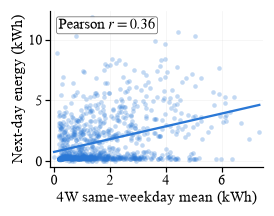

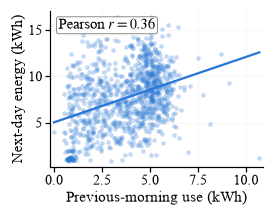

In [7]:
# Panels (a) and (b): same raw features, sample and trend as the reference paper version.
eda_scatter_rows = []
for circuit, suffix, xlabel, filename in [
    ("S2", "HP_swd4", "4W same-weekday mean (kWh)", "eda_laundry_weekly"),
    ("S3", "intra", "Previous-morning use (kWh)", "eda_waterac_morning"),
]:
    pair = eda_pair(circuit, suffix)
    r = pair.x.corr(pair.y)
    with plt.rc_context(EDA_STYLE):
        fig, ax = plt.subplots(figsize=(2.35, 1.82))
        ax.scatter(pair.x, pair.y, s=9, alpha=.28, color=C_BLUE, linewidths=0)
        if len(pair) > 1 and pair.x.std() > 0:
            slope, intercept = np.polyfit(pair.x, pair.y, deg=1)
            xx = np.linspace(pair.x.min(), pair.x.max(), 200)
            ax.plot(xx, slope * xx + intercept, color=C_BLUE, linewidth=1.5)
        ax.text(.04, .95, rf"Pearson $r={r:.2f}$", transform=ax.transAxes,
                ha="left", va="top", fontsize=9.5,
                bbox=dict(boxstyle="round,pad=0.13", facecolor="white",
                          edgecolor="0.30", linewidth=.45, alpha=.92))
        ax.set_xlabel(xlabel, labelpad=2)
        ax.set_ylabel("Next-day energy (kWh)", labelpad=2)
        ax.tick_params(axis="both", which="major", pad=2, length=3)
        ax.margins(x=.02, y=.04)
        fig.tight_layout(pad=.20)
        save_eda_figure(fig, filename)
    eda_scatter_rows.append({"figure": filename, "circuit": circuit, "feature": f"{circuit}_{suffix}",
                             "n": len(pair), "pearson_r": r})
    print(f"{filename} | Pearson r = {r:.6f} | n = {len(pair)}")
eda_scatter_summary = pd.DataFrame(eda_scatter_rows).set_index("figure")
save(eda_scatter_summary, "paper_eda_scatter_summary")

Highest feature redundancies (pre-2010 only):
Paper PDFs and PNG previews: /Users/alanliang/NYCU_course/115-1 Data Mining/proj1/figures/paper_ordered


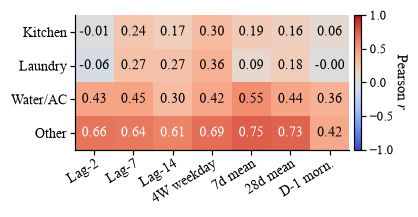

,feature_1,feature_2,pearson_r
0,Other_HP_swd4,Other_HP_roll28,0.918
1,Other_HP_roll7,Other_HP_roll28,0.908
2,Other_HP_lag14,Other_HP_swd4,0.867
3,Other_HP_lag7,Other_HP_roll7,0.856
4,Other_HP_lag2,Other_HP_roll7,0.842
5,Other_HP_lag7,Other_HP_swd4,0.842
6,Other_HP_swd4,Other_HP_roll7,0.820
7,Other_HP_lag14,Other_HP_roll28,0.813
8,Other_HP_lag7,Other_HP_roll28,0.792
9,S3_HP_swd4,S3_HP_roll28,0.787


In [8]:
# Panel (c): all four circuits and seven historical predictors, using the same EDA sample.
with plt.rc_context(EDA_STYLE):
    matrix = eda_corr.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(3.65, 1.82))
    im = ax.imshow(matrix, aspect="auto", vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(np.arange(len(eda_corr.columns)), eda_corr.columns,
                  rotation=31, ha="right", rotation_mode="anchor")
    ax.set_yticks(np.arange(len(eda_corr.index)), eda_corr.index)
    ax.tick_params(axis="both", pad=2, length=3)
    for i, j in np.ndindex(matrix.shape):
        value = matrix[i, j]
        ax.text(j, i, "NA" if np.isnan(value) else f"{value:.2f}", ha="center", va="center",
                fontsize=9, color="white" if abs(value) >= .58 else "black")
    ax.grid(False)
    cbar = fig.colorbar(im, ax=ax, fraction=.035, pad=.018)
    cbar.set_ticks([-1, -.5, 0, .5, 1])
    cbar.set_label(r"Pearson $r$", rotation=270, labelpad=9, fontsize=9.5)
    cbar.ax.tick_params(labelsize=8.5, pad=2)
    fig.tight_layout(pad=.16)
    save_eda_figure(fig, "eda_target_feature_corr")

# Quantify overlapping historical information (all 28 candidate histories).
eda_history = [f"{c}_{suffix}" for c in eda_labels for suffix in eda_suffixes.values()]
eda_feature_corr = XB.loc[eda_idx, eda_history].corr()
eda_redundancy = pd.DataFrame([
    {"feature_1": a, "feature_2": b, "pearson_r": eda_feature_corr.loc[a, b],
     "abs_r": abs(eda_feature_corr.loc[a, b])}
    for i, a in enumerate(eda_history) for b in eda_history[i + 1:]
    if pd.notna(eda_feature_corr.loc[a, b])
]).sort_values("abs_r", ascending=False).reset_index(drop=True)
eda_redundancy.to_csv(RESULTS / "paper_eda_feature_redundancy.csv", index=False)
print("Highest feature redundancies (pre-2010 only):")
display(eda_redundancy[["feature_1", "feature_2", "pearson_r"]].head(10).round(3))
print("Paper PDFs and PNG previews:", EDA_FIG_DIR)

## 4. §4：冬季平日尖峰占比

重現尖峰用電占比；保留原碼的逐小時完整觀測定義。

In [9]:
pre = E.index < "2010-01-01"
H = E[pre].resample("1h").sum(min_count=60)
mo, wd = H.index.month, H.index.dayofweek < 5
seasons = {"winter weekdays (Nov–Mar)": mo.isin([11, 12, 1, 2, 3]) & wd, "summer weekdays (Jun–Aug)": mo.isin([6, 7, 8]) & wd}
rows, profs = [], {}
for sname, mask in seasons.items():
    prof = H[mask].groupby(H[mask].index.hour)[COMPS].mean()
    profs[sname] = prof
    for c in COMPS:
        rows.append({"season": sname, "component": c, "kWh_per_day": prof[c].sum(),
                     "HP_06_22_share": prof.loc[6:21, c].sum() / prof[c].sum(),
                     "peak_hour": int(prof[c].idxmax())})
e0 = save(pd.DataFrame(rows).set_index(["season", "component"]), "E0_time_of_use")
display(e0)

winter_share = e0.loc["winter weekdays (Nov–Mar)", "HP_06_22_share"].loc[CIRC] * 100
display(save(winter_share.rename("HP_share_%").to_frame(), "paper_winter_HP_shares").round(2))


kWh_per_day  HP_06_22_share  peak_hour
season                    component                                        
winter weekdays (Nov–Mar) S1               1.356           0.855         20
                          S2               1.907           0.872         13
                          S3              10.109           0.882          8
                          Other           17.211           0.778         19
                          Global          30.583           0.822         20
summer weekdays (Jun–Aug) S1               1.118           0.797         19
                          S2               1.343           0.756         21
                          S3               6.562           0.830          8
                          Other            7.497           0.691         21
                          Global          16.520           0.759         21

,HP_share_%
component,
S1,85.490
S2,87.200
S3,88.240
Other,77.790


## 6. §5：特徵與模型定義

保留原特徵、Ridge 調參、樹模型與基準規則供後續實驗使用。

In [11]:
RAWC = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
CAL = GB["CAL"]
hol = pd.Series(daily.index.isin(HOL), index=daily.index).astype(float)

def build_ext(h):
    k0 = 1 if h == "A" else 2
    X = XS[h].copy(); G = XA_G if h == "A" else GB
    F = {"CAL": CAL, "NONCAL": [c for g in ["LAG", "SWD", "ROLL", "INTRA"] for c in G[g]]}
    F["RAW"] = []
    for c in RAWC:
        X[f"raw_{c}"] = RAWD[c].shift(k0); F["RAW"].append(f"raw_{c}")
    F["LOG"] = []
    for c in F["NONCAL"]:
        X[f"log_{c}"] = np.log1p(X[c].clip(lower=0)); F["LOG"].append(f"log_{c}")
    X["hol_D"], X["hol_Dm1"], X["hol_Dp1"] = hol, hol.shift(1).fillna(0), hol.shift(-1).fillna(0)
    X["bridge"] = (daily.index.dayofweek.isin([0, 4]) & ((hol.shift(1).fillna(0) > 0) | (hol.shift(-1).fillna(0) > 0))).astype(float)
    F["HOL"] = ["hol_D", "hol_Dm1", "hol_Dp1", "bridge"]
    g = daily["Global_day"]
    ratio = g.shift(k0) / g.shift(k0).rolling(28, min_periods=14).median()
    low = (g / g.shift(1).rolling(28, min_periods=14).median() < .6).astype(float).where(g.notna())
    run = low.groupby((low != 1).cumsum()).cumsum()
    part = daily["Global_morning"] if h == "B" else daily["Global_evening"]
    X["away_ratio"] = ratio
    X["away_flag"] = (ratio < .6).astype(float).where(ratio.notna())
    X["away_run"] = run.shift(k0)
    X["away_ratio_latest_part"] = part.shift(1) / part.shift(2).rolling(28, min_periods=14).median()
    F["AWAY"] = ["away_ratio", "away_flag", "away_run", "away_ratio_latest_part"]
    F["ROUT"] = []
    pos = pd.Series(np.arange(len(daily)), index=daily.index)
    for c, q in [("S2", 2.0), ("S1", 2.0)]:
        big = (daily[f"{c}_day"] > q).astype(float).where(daily[f"{c}_day"].notna())
        last = pos.where(big.fillna(0) > 0).ffill()
        X[f"{c}_days_since_big"] = (pos - last).shift(k0).clip(upper=28)
        X[f"{c}_big_count14"] = big.shift(k0).rolling(14, min_periods=7).sum()
        F["ROUT"] += [f"{c}_days_since_big", f"{c}_big_count14"]
    F["LOGROB"] = []
    for c in CIRC:
        hp = daily[f"{c}_HP"]
        X[f"log_{c}_HP_swdmed4"] = np.log1p(pd.concat([hp.shift(7 * w) for w in range(1, 5)], axis=1).median(axis=1))
        X[f"log_{c}_HP_ewm7"] = np.log1p(hp.shift(k0).ewm(span=7, min_periods=4).mean())
        F["LOGROB"] += [f"log_{c}_HP_swdmed4", f"log_{c}_HP_ewm7"]
    return X, F

XA_G = GA
XEX = {}; FX = {}
for h in ("A", "B"):
    XEX[h], FX[h] = build_ext(h)
F = FX["B"]
assert len(F["NONCAL"]) == 36 and len(CAL) == 10
own = lambda t, cols: [c for c in cols if c.startswith(f"{t}_") or c.startswith(f"log_{t}_")]

def feats_C7(h):
    Fh = FX[h]
    return lambda t, tr: (CAL + Fh["HOL"] + Fh["AWAY"] + Fh["ROUT"]
                          + (own(t, Fh["LOG"] + Fh["LOGROB"]) if t in CIRC else Fh["LOG"] + Fh["LOGROB"]))
print({t: len(feats_C7("B")(t, None)) for t in ["S1", "S2", "S3", "Other", "Global"]})

{'S1': 33, 'S2': 33, 'S3': 33, 'Other': 33, 'Global': 66}


In [12]:
TEST_START = pd.Timestamp("2010-01-01")
def make_folds(index, val_days=120, n=4, warmup=28):
    start = index.min() + pd.Timedelta(days=warmup); end = TEST_START - pd.Timedelta(days=1)
    out = []
    for i in range(n):
        ve = end - pd.Timedelta(days=(n - 1 - i) * val_days); vs = ve - pd.Timedelta(days=val_days - 1)
        out.append((start, vs - pd.Timedelta(days=1), vs, ve))
    return out
FOLDS = make_folds(daily.index)
def dates(a, b):
    return daily.index[(daily.index >= a) & (daily.index <= b) & daily.valid]
SPLITS = [(f"fold{i+1}", dates(a, b), dates(c, d)) for i, (a, b, c, d) in enumerate(FOLDS)]
PRE = dates(daily.index.min() + pd.Timedelta(days=28), TEST_START - pd.Timedelta(days=1))
TEST = dates(TEST_START, daily.index.max())
SPLITS_ALL = SPLITS + [("test", PRE, TEST)]


ALPHAS = np.logspace(-2, 4, 13)
log1p_c = lambda y: np.log1p(np.clip(y, 0, None))
def ridge(log=False):
    p = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler()), ("reg", Ridge())])
    grid = {"reg__alpha": ALPHAS}
    if log:
        p = TransformedTargetRegressor(regressor=p, func=log1p_c, inverse_func=np.expm1)
        grid = {"regressor__reg__alpha": ALPHAS}
    return GridSearchCV(p, grid, cv=TimeSeriesSplit(3), scoring="neg_mean_absolute_error")
def ols():
    return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler()), ("reg", LinearRegression())])
def hgb():
    return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                     ("reg", HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=15,
                                                           min_samples_leaf=12, l2_regularization=1.0, random_state=SEED))])
def rf():
    return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                     ("reg", RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_features=.7, n_jobs=-1, random_state=SEED))])

P = {}          # P[(split, model, target)] = pd.Series of predictions
TYPE = {}       # model -> BASELINE / LINEAR / NONLINEAR
TARGETS = COMPS

def fit_model(name, kind, factory, feats=None, h=None, targets=TARGETS, splits=SPLITS_ALL):
    TYPE[name] = kind
    t0 = time.time()
    for s, tr, va in splits:
        for t in targets:
            y = daily[f"{t}_HP"]
            X = XS[h][feats]
            mdl = factory().fit(X.loc[tr], y.loc[tr])
            P[(s, name, t)] = pd.Series(mdl.predict(X.loc[va]), index=va)
    print(f"{name:<34s} done ({time.time()-t0:.1f}s)")

def lookup_pred(y_tr, va):
    tmp = pd.DataFrame({"y": y_tr, "m": y_tr.index.month, "w": y_tr.index.dayofweek})
    mw = tmp.groupby(["m", "w"]).y.agg(["mean", "count"]); wd = tmp.groupby("w").y.mean(); mu = tmp.y.mean()
    return np.array([mw.loc[(d.month, d.dayofweek), "mean"] if (d.month, d.dayofweek) in mw.index and mw.loc[(d.month, d.dayofweek), "count"] >= 5
                     else wd.get(d.dayofweek, mu) for d in va])

def add_baselines():
    for name in ["Train mean", "Persistence [A]", "Persistence [B]", "Weekly persistence", "Month×weekday lookup", "Same-weekday 4w mean"]:
        TYPE[name] = "BASELINE"
    for s, tr, va in SPLITS_ALL:
        for t in TARGETS:
            y = daily[f"{t}_HP"]; mu = y.loc[tr].mean()
            P[(s, "Train mean", t)] = pd.Series(mu, index=va)
            P[(s, "Persistence [A]", t)] = y.shift(1).reindex(va).fillna(mu)
            P[(s, "Persistence [B]", t)] = y.shift(2).reindex(va).fillna(mu)
            P[(s, "Weekly persistence", t)] = y.shift(7).reindex(va).fillna(mu)
            P[(s, "Month×weekday lookup", t)] = pd.Series(lookup_pred(y.loc[tr], va), index=va)
            P[(s, "Same-weekday 4w mean", t)] = pd.concat([y.shift(7 * w) for w in range(1, 5)], axis=1).mean(axis=1).reindex(va).fillna(mu)

def scores(models, which="cv", subset="all", targets=TARGETS):
    # 回傳 MAE（kWh）與 nMAE（MAE / 該 split 訓練均值）；subset: all / red
    rows = []
    split_list = SPLITS if which == "cv" else [SPLITS_ALL[-1]]
    for mname in models:
        for s, tr, va in split_list:
            for t in targets:
                p = P[(s, mname, t)]
                idx = p.index if subset == "all" else p.index[daily.red_eligible.reindex(p.index).values]
                if len(idx) == 0:
                    continue
                y = daily.loc[idx, f"{t}_HP"]
                mae = mean_absolute_error(y, p.loc[idx])
                rows.append({"model": mname, "split": s, "target": t, "n": len(idx), "MAE": mae,
                             "RMSE": mean_squared_error(y, p.loc[idx]) ** .5, "bias": float((p.loc[idx] - y).mean()),
                             "nMAE": mae / daily.loc[tr, f"{t}_HP"].mean()})
    return pd.DataFrame(rows)

def summary(models, which="cv", subset="all"):
    sc = scores(models, which, subset)
    tab = sc.pivot_table(index="model", columns="target", values="MAE", aggfunc="mean")[TARGETS]
    circ = sc[sc.target.isin(CIRC)]
    if which == "cv":   # 依 split 加權：每個 split 先算 4 分路的平均 nMAE
        per = circ.groupby(["model", "split"]).nMAE.mean().unstack()
        tab["macro_nMAE_circuits"] = per.mean(axis=1); tab["fold_sd"] = per.std(axis=1, ddof=1)
    else:
        tab["macro_nMAE_circuits"] = circ.groupby("model").nMAE.mean()
    tab["type"] = [TYPE[mm] for mm in tab.index]
    return tab.sort_values("macro_nMAE_circuits")

def fit_custom(name, kind, feat_fn, factory, h="B", splits=SPLITS_ALL):
    TYPE[name] = kind; X = XEX[h]; t0 = time.time()
    for s, tr, va in splits:
        for t in TARGETS:
            f = feat_fn(t, tr)
            mdl = factory().fit(X.loc[tr, f], daily.loc[tr, f"{t}_HP"])
            P[(s, name, t)] = pd.Series(mdl.predict(X.loc[va, f]), index=va)
    print(f"{name:<40s} done ({time.time()-t0:.1f}s)")

def topk_corr(t, tr, pool, k=5):
    r = XEX["B"].loc[tr, pool].corrwith(daily.loc[tr, f"{t}_HP"]).abs().sort_values(ascending=False)
    return list(r.index[:k])

def fold_macro(name, sub):
    sc = scores([name], "cv", sub); sc = sc[sc.target.isin(CIRC)]
    return sc.groupby("split").nMAE.mean()

SPL = {s: (tr, va) for s, tr, va in SPLITS_ALL}
FINAL = "Ours (C7)"
add_baselines()

## 7. §6：切分、指標與行動門檻

核對 CV／test 日數，並計算不同麻煩成本的分路門檻。

In [13]:
display(pd.DataFrame([{"split": s, "train_n": len(tr), "val_n": len(va), "val_red_eligible": int(daily.red_eligible.reindex(va).sum()),
                       "val_start": va.min().date(), "val_end": va.max().date()} for s, tr, va in SPLITS_ALL]))
split_table = pd.DataFrame([{"split": s, "train_n": len(tr), "val_n": len(va),
    "val_red_eligible": int(daily.red_eligible.reindex(va).sum()),
    "val_start": va.min().date(), "val_end": va.max().date()} for s, tr, va in SPLITS_ALL])
save(split_table, "paper_chronological_splits")


,split,train_n,val_n,val_red_eligible,val_start,val_end
0,fold1,574,114,40,2008-09-08,2009-01-05
1,fold2,688,113,58,2009-01-06,2009-05-05
2,fold3,801,113,0,2009-05-06,2009-09-02
3,fold4,914,115,40,2009-09-03,2009-12-31
4,test,1029,304,76,2010-01-01,2010-11-25


In [14]:
DEC = ["S1", "S2"]; FDEC = {"S1": .5, "S2": 1.0}
def base_load(tr):
    return {c: 16 * daily.loc[tr, f"{c}_night"].median() / 3 for c in ["S1", "S2", "S3"]}

# 門檻表（kWh），用 test 的訓練資料（2010 年前）估常駐用電
bt = base_load(SPL["test"][0])
thr = pd.DataFrame({f"tau={t}": {c: bt[c] + t / (SAVE_PER_KWH * FDEC[c]) for c in DEC} for t in [.25, .5, 1.0]})
save(thr, "final_thresholds_kWh"); display(thr.round(2))


,tau=0.25,tau=0.5,tau=1.0
S1,0.880,1.760,3.520
S2,0.730,1.170,2.050


## 8. §6／表3：預測方法比較

沿用相同訓練程序，依論文列序輸出四種評估範圍。

In [15]:
fit_custom("Calendar only", "LINEAR", lambda t, tr: CAL, lambda: ridge(True))
fit_custom("Raw", "LINEAR", lambda t, tr: F["RAW"], lambda: ridge(True))
fit_custom("Raw + calendar", "LINEAR", lambda t, tr: F["RAW"] + CAL, lambda: ridge(True))
fit_custom("Top-5", "LINEAR", lambda t, tr: topk_corr(t, tr, F["NONCAL"]), lambda: ridge(True))
fit_custom("Top-5 + calendar", "LINEAR", lambda t, tr: topk_corr(t, tr, F["NONCAL"]) + CAL, lambda: ridge(True))
fit_custom(FINAL, "LINEAR", feats_C7("B"), lambda: ridge(True))
fit_custom("RF + Raw + calendar", "NONLINEAR", lambda t, tr: F["RAW"] + CAL, rf)
fit_custom("RF + Ours features", "NONLINEAR", feats_C7("B"), rf)
fit_custom("HGB + Ours features", "NONLINEAR", feats_C7("B"), hgb)
MAIN = ["Calendar only", "Raw", "Raw + calendar", "Top-5", "Top-5 + calendar", FINAL, "RF + Raw + calendar", "RF + Ours features", "HGB + Ours features",
        "Same-weekday 4w mean", "Month×weekday lookup", "Persistence [B]"]
R = {(w, s): summary(MAIN, w, s) for w in ("cv", "test") for s in ("red", "all")}
main = pd.DataFrame({"n_features (circuit)": [len(CAL), len(F["RAW"]), 14, 5, 15, len(feats_C7("B")("S2", None)), 14, len(feats_C7("B")("S2", None)),
                                            len(feats_C7("B")("S2", None)), 0, 0, 0]}, index=MAIN)
for (w, s), r in R.items():
    main[f"{w}_{s}"] = r.macro_nMAE_circuits
    if w == "cv":
        main[f"{w}_{s}_sd"] = r.fold_sd
main["type"] = [TYPE[m_] for m_ in MAIN]
main = main[["type", "n_features (circuit)", "cv_red", "cv_red_sd", "test_red", "cv_all", "cv_all_sd", "test_all"]]
save(main, "final_main_comparison")
for which in ("cv", "test"):
    save(R[(which, "red")].loc[MAIN], f"final_{which}_red_by_circuit")
paper_methods = [FINAL, "Top-5 + calendar", "Top-5", "Calendar only", "Raw + calendar", "Raw",
                 "RF + Ours features", "HGB + Ours features", "RF + Raw + calendar",
                 "Same-weekday 4w mean", "Persistence [B]"]
paper_main = main.loc[paper_methods, ["cv_red", "cv_red_sd", "test_red", "cv_all", "test_all"]]
display(save(paper_main, "paper_table3_forecast_comparison").round(3))
print("main.tex 的 RF + Raw + calendar/test_red 為 0.508；此處保留原程式重算值。")


Calendar only                            done (2.1s)
Raw                                      done (2.0s)
Raw + calendar                           done (2.1s)
Top-5                                    done (2.1s)
Top-5 + calendar                         done (2.3s)
Ours (C7)                                done (2.9s)
RF + Raw + calendar                      done (4.0s)
RF + Ours features                       done (5.8s)
HGB + Ours features                      done (14.8s)
main.tex 的 RF + Raw + calendar/test_red 為 0.508；此處保留原程式重算值。


  File "/Users/alanliang/NYCU_course/115-1 Data Mining/proj1/.venv/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/alanliang/NYCU_course/115-1 Data Mining/proj1/.venv/lib/python3.13/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


,cv_red,cv_red_sd,test_red,cv_all,test_all
Ours (C7),0.455,0.020,0.454,0.450,0.423
Top-5 + calendar,0.466,0.014,0.478,0.457,0.438
Top-5,0.472,0.019,0.491,0.468,0.451
Calendar only,0.494,0.008,0.507,0.487,0.473
Raw + calendar,0.504,0.009,0.503,0.483,0.461
Raw,0.544,0.025,0.538,0.525,0.494
RF + Ours features,0.490,0.032,0.479,0.482,0.446
HGB + Ours features,0.513,0.046,0.471,0.510,0.451
RF + Raw + calendar,0.563,0.056,0.509,0.524,0.477
Same-weekday 4w mean,0.471,0.040,0.517,0.490,0.497


## 9. §7.1：11:00 與午夜比較

比較同模型在兩種資訊截止時間的誤差與相對成本。

In [16]:
fit_custom("Ours (C7) [A]", "LINEAR", feats_C7("A"), lambda: ridge(True), h="A")
hz = pd.DataFrame({f"{w}_{s}": summary(["Ours (C7) [A]", FINAL, "Persistence [A]", "Persistence [B]"], w, s).macro_nMAE_circuits
                   for w in ("cv", "test") for s in ("red", "all")})
save(hz, "final_horizon"); display(hz.round(3))
print("cost of deciding at 11:00 (CV red): %+.1f%%" % (100 * (hz.loc[FINAL, "cv_red"] / hz.loc["Ours (C7) [A]", "cv_red"] - 1)))

Ours (C7) [A]                            done (3.1s)
cost of deciding at 11:00 (CV red): +1.0%


,cv_red,cv_all,test_red,test_all
model,,,,
Ours (C7) [A],0.450,0.447,0.438,0.414
Ours (C7),0.455,0.450,0.454,0.423
Persistence [A],0.728,0.637,0.751,0.603
Persistence [B],0.832,0.680,0.806,0.619


## 10. §7.1：逐 fold 與 bootstrap

輸出逐 fold 勝負及七筆觀測區塊的配對誤差信賴區間。

In [17]:
rows = []
for b in ["Calendar only", "Top-5 + calendar", "Raw + calendar", "Same-weekday 4w mean", "Month×weekday lookup", "RF + Ours features", "HGB + Ours features"]:
    for sub in ("red", "all"):
        d = fold_macro(FINAL, sub) - fold_macro(b, sub)
        rows.append({"vs": b, "subset": sub, "mean_diff": d.mean(), "folds_Ours_better": f"{int((d < 0).sum())}/{len(d)}",
                     "per_fold": " ".join(f"{v:+.3f}" for v in d.values)})
h2h = save(pd.DataFrame(rows), "final_head_to_head"); display(h2h.round(3))

def block_boot(a, b, t, sub, B=3000, block=7, seed=42):
    rng = np.random.default_rng(seed)
    pa, pb = P[("test", a, t)], P[("test", b, t)]
    days = pa.index if sub == "all" else pa.index[daily.red_eligible.reindex(pa.index).values]
    y = daily.loc[days, f"{t}_HP"]
    d = ((pa.loc[days] - y).abs() - (pb.loc[days] - y).abs()).values
    n = len(d); st_ = np.arange(n - block + 1)
    bs = [d[np.concatenate([np.arange(s, s + block) for s in rng.choice(st_, n // block + 1)])[:n]].mean() for _ in range(B)]
    return {"vs": b, "target": t, "subset": sub, "n": n, "mean_diff_kWh": d.mean(), "CI_low": np.quantile(bs, .025), "CI_high": np.quantile(bs, .975)}
bb = pd.DataFrame([block_boot(FINAL, b, t, "red") for b in ["Top-5 + calendar", "Same-weekday 4w mean"] for t in TARGETS])
bb["significant"] = (bb.CI_high < 0) | (bb.CI_low > 0)
save(bb, "final_block_bootstrap"); display(bb.round(3))

,vs,subset,mean_diff,folds_Ours_better,per_fold
0,Calendar only,red,-0.039,3/3,-0.040 -0.051 -0.026
1,Calendar only,all,-0.037,4/4,-0.043 -0.037 -0.029 -0.039
2,Top-5 + calendar,red,-0.011,3/3,-0.011 -0.017 -0.005
3,Top-5 + calendar,all,-0.007,4/4,-0.007 -0.013 -0.000 -0.009
4,Raw + calendar,red,-0.049,3/3,-0.057 -0.063 -0.027
5,Raw + calendar,all,-0.033,4/4,-0.033 -0.046 -0.018 -0.037
6,Same-weekday 4w mean,red,-0.016,2/3,-0.030 +0.009 -0.026
7,Same-weekday 4w mean,all,-0.040,4/4,-0.072 -0.021 -0.050 -0.017
8,Month×weekday lookup,red,-0.112,3/3,-0.133 -0.109 -0.094
9,Month×weekday lookup,all,-0.082,4/4,-0.086 -0.061 -0.121 -0.061


,vs,target,subset,n,mean_diff_kWh,CI_low,CI_high,significant
0,Top-5 + calendar,S1,red,76,-0.019,-0.041,-0.005,True
1,Top-5 + calendar,S2,red,76,-0.038,-0.076,-0.002,True
2,Top-5 + calendar,S3,red,76,-0.259,-0.659,0.124,False
3,Top-5 + calendar,Other,red,76,-0.233,-0.401,-0.126,True
4,Top-5 + calendar,Global,red,76,-1.539,-2.357,-1.011,True
5,Same-weekday 4w mean,S1,red,76,-0.151,-0.241,-0.010,True
6,Same-weekday 4w mean,S2,red,76,-0.103,-0.311,0.148,False
7,Same-weekday 4w mean,S3,red,76,-0.266,-0.875,0.187,False
8,Same-weekday 4w mean,Other,red,76,-0.432,-0.790,-0.060,True
9,Same-weekday 4w mean,Global,red,76,-0.487,-1.487,0.421,False


## 11. §7.1／表4：特徵消融

固定 Ridge-log，依論文順序逐步加入特徵。

In [18]:
steps = [
    ("S0 all 46 features", lambda t, tr: CAL + F["NONCAL"]),
    ("S1 own-circuit only", lambda t, tr: CAL + (own(t, F["NONCAL"]) if t in CIRC else F["NONCAL"])),
    ("S2 + log features", lambda t, tr: CAL + (own(t, F["LOG"]) if t in CIRC else F["LOG"])),
    ("S3 + holidays", lambda t, tr: CAL + F["HOL"] + (own(t, F["LOG"]) if t in CIRC else F["LOG"])),
    ("S4 + away / return", lambda t, tr: CAL + F["HOL"] + F["AWAY"] + (own(t, F["LOG"]) if t in CIRC else F["LOG"])),
]
for nm, fn in steps:
    fit_custom(nm, "LINEAR", fn, lambda: ridge(True))
STEPS = [nm for nm, _ in steps] + [FINAL]
st = pd.DataFrame({f"{w}_{s}": summary(STEPS, w, s).macro_nMAE_circuits for w in ("cv", "test") for s in ("red", "all")}).loc[STEPS]
prev = None; wins = []
for nm in STEPS:
    if prev is None: wins.append("")
    else:
        d = fold_macro(nm, "red") - fold_macro(prev, "red"); wins.append(f"{int((d < 0).sum())}/{len(d)}")
    prev = nm
st["CV red folds better than previous step"] = wins
save(st, "final_feature_steps"); display(st.round(3))

S0 all 46 features                       done (2.9s)
S1 own-circuit only                      done (2.4s)
S2 + log features                        done (2.6s)
S3 + holidays                            done (2.6s)
S4 + away / return                       done (2.7s)


,cv_red,cv_all,test_red,test_all,CV red folds better than previous step
model,,,,,
S0 all 46 features,0.479,0.462,0.459,0.427,
S1 own-circuit only,0.467,0.456,0.466,0.432,2/3
S2 + log features,0.458,0.451,0.464,0.428,3/3
S3 + holidays,0.457,0.450,0.463,0.427,2/3
S4 + away / return,0.455,0.450,0.461,0.426,2/3
Ours (C7),0.455,0.450,0.454,0.423,1/3


## 12. §7.2／表5：決策收益

掃描麻煩成本，輸出每年收益及動作次數；一年按二十二紅日。

In [19]:
def collect(circ, which, models):
    names = [s for s, _, _ in SPLITS] if which == "cv" else ["test"]
    out = []
    for s in names:
        tr, va = SPL[s]; red = va[daily.red_eligible.reindex(va).values]
        if not len(red): continue
        b = base_load(tr)[circ]
        df = pd.DataFrame({"split": s, "actual": np.maximum(0, daily.loc[red, f"{circ}_HP"] - b)}, index=red)
        for m_ in models: df[m_] = np.maximum(0, P[(s, m_, circ)].loc[red] - b)
        out.append(df)
    return pd.concat(out)
POL = [FINAL, "Top-5 + calendar", "Same-weekday 4w mean", "Month×weekday lookup", "RF + Ours features"]
DC = {w: {c: collect(c, w, POL) for c in DEC} for w in ("cv", "test")}
def evaluate(which, tau):
    d = DC[which]; n = len(d["S2"]); rows = []
    for pol in ["Oracle (perfect forecast)"] + POL + ["Always shift", "Never shift"]:
        v = k = wrong = 0
        for c, dd in d.items():
            g = SAVE_PER_KWH * FDEC[c] * dd.actual
            if pol == "Always shift": act = np.ones(len(dd), bool)
            elif pol == "Never shift": act = np.zeros(len(dd), bool)
            elif pol.startswith("Oracle"): act = (g >= tau).values
            else: act = (SAVE_PER_KWH * FDEC[c] * dd[pol] >= tau).values
            v += float(((g - tau) * act).sum()); k += int(act.sum()); wrong += int(((g >= tau).values != act).sum())
        rows.append({"set": which, "tau": tau, "policy": pol, "net_eur_per_red_day": v / n, "net_eur_per_year_22": 22 * v / n,
                     "actions_per_year_22": 22 * k / n, "wrong_%": 100 * wrong / (2 * n)})
    return rows
TAUS = np.round(np.arange(0, 2.001, .05), 2)
curve = save(pd.DataFrame([r for w in ("cv", "test") for t in TAUS for r in evaluate(w, t)]), "final_decision_curve")
tab = curve[curve.tau.isin([.25, .5, 1.0])]
save(tab, "final_decision_table")
for col in ["net_eur_per_year_22", "actions_per_year_22"]:
    print(col); display(tab.pivot_table(index="policy", columns=["set", "tau"], values=col).round(1))
# 預測划算的 τ 範圍（比「每次都改／都不改」中較好者多 > 0.05 €/天）
rows = []
for w in ("cv", "test"):
    pv = curve[curve.set.eq(w)].pivot_table(index="tau", columns="policy", values="net_eur_per_red_day")
    best = pv[["Always shift", "Never shift"]].max(axis=1)
    for pol in POL + ["Oracle (perfect forecast)"]:
        g = pv[pol] - best; ok = g[g > .05].index
        rows.append({"set": w, "policy": pol, "tau_range_gain>0.05": f"{ok.min():.2f}–{ok.max():.2f}" if len(ok) else "none",
                     "mean_gain_tau_0.1_1.5": g.loc[.1:1.5].mean(), "max_gain": g.max()})
rng_ = save(pd.DataFrame(rows), "final_decision_curve_summary"); display(rng_.round(3))
paper_policies = ["Oracle (perfect forecast)", FINAL, "Top-5 + calendar", "Same-weekday 4w mean", "Always shift", "Never shift"]
paper_decision = curve[curve.tau.eq(.5)].pivot(index="policy", columns="set", values=["net_eur_per_year_22", "actions_per_year_22"]).loc[paper_policies]
paper_decision = paper_decision.reindex(columns=pd.MultiIndex.from_product([
    ["net_eur_per_year_22", "actions_per_year_22"], ["cv", "test"]], names=paper_decision.columns.names))
display(save(paper_decision, "paper_table5_decision_tau_0_5").round(1))


net_eur_per_year_22
actions_per_year_22


set                           cv                  test               
tau                        0.250  0.500   1.000  0.250  0.500   1.000
policy                                                               
Always shift               7.500 -3.500 -25.500 10.200 -0.800 -22.800
Month×weekday lookup       6.300  1.300  -2.800  8.500  3.900  -0.200
Never shift                0.000  0.000   0.000  0.000  0.000   0.000
Oracle (perfect forecast) 13.300 10.100   6.700 15.300 11.900   8.500
Ours (C7)                  7.600  4.700   1.500  8.400  4.700   1.300
RF + Ours features         7.200  2.900   3.000 10.900  5.700   1.100
Same-weekday 4w mean       7.800  3.300   2.700  9.600  5.800   1.500
Top-5 + calendar           7.500  4.300   1.100 10.100  5.700   2.000

set                           cv                 test              
tau                        0.250  0.500  1.000  0.250  0.500  1.000
policy                                                             
Always shift              44.000 44.000 44.000 44.000 44.000 44.000
Month×weekday lookup      36.000 16.900  9.900 30.400 14.800 10.400
Never shift                0.000  0.000  0.000  0.000  0.000  0.000
Oracle (perfect forecast) 18.700  9.400  4.800 18.500  9.800  5.200
Ours (C7)                 34.400  7.200  1.800 30.400  6.100  1.200
RF + Ours features        38.900 13.400  4.600 36.800 11.900  4.300
Same-weekday 4w mean      23.000  9.900  3.800 23.400 11.600  5.800
Top-5 + calendar          35.100  7.700  1.600 30.700  5.800  1.400

,set,policy,tau_range_gain>0.05,mean_gain_tau_0.1_1.5,max_gain
0,cv,Ours (C7),0.35–1.15,0.074,0.223
1,cv,Top-5 + calendar,0.30–1.20,0.078,0.212
2,cv,Same-weekday 4w mean,0.35–1.70,0.109,0.189
3,cv,Month×weekday lookup,0.40–0.60,-0.065,0.090
4,cv,RF + Ours features,0.40–1.35,0.085,0.140
5,cv,Oracle (perfect forecast),0.05–2.00,0.311,0.483
6,test,Ours (C7),0.35–1.05,0.077,0.232
7,test,Top-5 + calendar,0.35–1.05,0.072,0.258
8,test,Same-weekday 4w mean,0.35–1.25,0.079,0.263
9,test,Month×weekday lookup,0.40–1.35,0.031,0.175


net_eur_per_year_22        actions_per_year_22       
set                                        cv   test                  cv   test
policy                                                                         
Oracle (perfect forecast)              10.100 11.900               9.400  9.800
Ours (C7)                               4.700  4.700               7.200  6.100
Top-5 + calendar                        4.300  5.700               7.700  5.800
Same-weekday 4w mean                    3.300  5.800               9.900 11.600
Always shift                           -3.500 -0.800              44.000 44.000
Never shift                             0.000  0.000               0.000  0.000

## 13. §7.3：Water/AC 預熱

以 CV 選預熱倍率與固定量，比較每日及年化節省。

In [20]:
C_TANK = 17.0
def preheat_saving(a, q, C=C_TANK):
    q = np.clip(np.asarray(q, float), 0, C); a = np.asarray(a, float)
    return PRICE["red_HP"] * a - (PRICE["red_HC"] * q + PRICE["red_HP"] * np.maximum(0, a - q))
S3 = {w: collect("S3", w, [FINAL, "Same-weekday 4w mean"]) for w in ("cv", "test")}
GM = np.round(np.arange(.5, 2.51, .05), 2); GK = np.arange(0, 30.1, .5)
rows = [{"policy": "Oracle", "param": "q = actual", **{w: preheat_saving(S3[w].actual, S3[w].actual).mean() for w in S3}}]
for m_ in [FINAL, "Same-weekday 4w mean"]:
    mb = GM[int(np.argmax([preheat_saving(S3["cv"].actual, g * S3["cv"][m_]).mean() for g in GM]))]
    rows.append({"policy": m_, "param": f"m={mb}", **{w: preheat_saving(S3[w].actual, mb * S3[w][m_]).mean() for w in S3}})
kb = GK[int(np.argmax([preheat_saving(S3["cv"].actual, np.full(len(S3["cv"]), k)).mean() for k in GK]))]
rows.append({"policy": "Fixed amount", "param": f"q={kb} kWh", **{w: preheat_saving(S3[w].actual, np.full(len(S3[w]), kb)).mean() for w in S3}})
rows.append({"policy": "Fill the tank", "param": f"q={C_TANK}", **{w: preheat_saving(S3[w].actual, np.full(len(S3[w]), C_TANK)).mean() for w in S3}})
heat = pd.DataFrame(rows).set_index("policy")
heat["cv_eur_per_year_22"] = 22 * heat.cv; heat["test_eur_per_year_22"] = 22 * heat.test
save(heat, "final_heater_preheat"); display(heat.round(2))

,param,cv,test,cv_eur_per_year_22,test_eur_per_year_22
policy,,,,,
Oracle,q = actual,5.070,5.570,111.540,122.620
Ours (C7),m=1.3,4.450,4.840,97.900,106.460
Same-weekday 4w mean,m=1.3,4.460,4.870,98.060,107.200
Fixed amount,q=11.0 kWh,4.540,4.890,99.910,107.520
Fill the tank,q=17.0,3.770,4.410,82.850,97.080


## 14. §8.1／表6：OLS 效果與 VIF

使用訓練期 OLS 與 Newey–West，輸出完整係數及論文十三列。

In [21]:
import statsmodels.api as sm
WD = {f"wd_{k}": n for k, n in zip(range(1, 7), ["Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])}
rows = []
for c in CIRC:
    f = feats_C7("B")(c, None)
    X = XEX["B"].loc[PRE, f]; y = log1p_c(daily.loc[PRE, f"{c}_HP"])
    keep = X.std() > 1e-9; X = X.loc[:, keep]
    ok = X.notna().all(axis=1) & y.notna(); X = X[ok]
    cont = [k for k in X.columns if not (k.startswith("wd_") or k.startswith("hol_") or k in ("bridge", "away_flag"))]
    Z = X.copy(); Z[cont] = (X[cont] - X[cont].mean()) / X[cont].std()
    res = sm.OLS(y[ok], sm.add_constant(Z)).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    Zc = sm.add_constant(Z).values; ci = res.conf_int()
    for i, k in enumerate(Z.columns):
        rows.append({"circuit": c, "feature": WD.get(k, k), "effect_%": 100 * (np.exp(res.params[k]) - 1),
                     "CI_low_%": 100 * (np.exp(ci.loc[k, 0]) - 1), "CI_high_%": 100 * (np.exp(ci.loc[k, 1]) - 1),
                     "p_value": res.pvalues[k], "VIF": variance_inflation_factor(Zc, i + 1), "n": int(ok.sum()), "R2_log": res.rsquared})
coef = save(pd.DataFrame(rows), "final_coefficients")
for c in CIRC:
    t_ = coef[coef.circuit.eq(c)].sort_values("p_value")
    print(f"\n{LABEL[c]}  n={t_.n.iloc[0]}  R²(log)={t_.R2_log.iloc[0]:.3f}  — 10 smallest p-values")
    display(t_.head(10).set_index("feature")[["effect_%", "CI_low_%", "CI_high_%", "p_value", "VIF"]].round(3))
paper_coef_keys = [("S1", "Sun"), ("S1", "Sat"), ("S1", "hol_D"), ("S1", "bridge"),
    ("S2", "Sun"), ("S2", "Wed"), ("S2", "Tue"), ("S2", "away_flag"),
    ("S3", "ann_cos1"), ("S3", "bridge"), ("S3", "hol_Dm1"), ("S3", "log_S3_intra"), ("Other", "ann_cos1")]
paper_coef = coef.set_index(["circuit", "feature"]).loc[paper_coef_keys,
    ["effect_%", "CI_low_%", "CI_high_%", "p_value", "VIF", "n"]]
display(save(paper_coef, "paper_table6_selected_coefficients").round(3))



Kitchen (S1)  n=813  R²(log)=0.245  — 10 smallest p-values

Laundry (S2)  n=813  R²(log)=0.226  — 10 smallest p-values

Water heater/AC (S3)  n=813  R²(log)=0.531  — 10 smallest p-values

Unmetered (Other)  n=813  R²(log)=0.763  — 10 smallest p-values


,effect_%,CI_low_%,CI_high_%,p_value,VIF
feature,,,,,
Sun,63.102,39.947,90.089,0.000,2.223
Sat,60.036,35.504,89.009,0.000,2.593
hol_D,40.175,17.118,67.770,0.000,1.057
Wed,27.135,9.527,47.574,0.002,2.206
bridge,58.482,10.154,128.014,0.013,1.666
ann_sin1,4.379,0.852,8.029,0.015,1.287
away_flag,-21.520,-39.126,1.177,0.062,2.159
ann_cos1,3.902,-0.223,8.198,0.064,1.413
away_ratio_latest_part,3.208,-1.011,7.607,0.138,2.203


,effect_%,CI_low_%,CI_high_%,p_value,VIF
feature,,,,,
Sun,44.945,23.238,70.476,0.000,2.036
Tue,28.840,11.655,48.669,0.001,2.061
Wed,32.165,11.087,57.242,0.002,2.148
Sat,30.841,10.530,54.883,0.002,2.179
log_S2_HP_roll7,-13.490,-24.629,-0.705,0.039,12.154
log_S2_HP_lag7,6.897,-0.196,14.495,0.057,2.463
away_flag,-20.010,-36.735,1.137,0.062,2.032
log_S2_HP_roll28,7.842,-1.067,17.553,0.086,5.617
log_S2_HP_swdmed4,8.359,-2.079,19.910,0.120,7.369


,effect_%,CI_low_%,CI_high_%,p_value,VIF
feature,,,,,
ann_cos1,6.994,3.827,10.258,0.000,1.994
log_S3_HP_roll28,-12.650,-19.662,-5.026,0.002,13.408
bridge,46.342,11.795,91.566,0.006,1.679
S1_days_since_big,-4.611,-7.968,-1.132,0.010,2.630
log_S3_intra,5.720,0.892,10.779,0.020,3.240
hol_Dm1,-20.632,-34.847,-3.317,0.022,1.607
S2_big_count14,-3.240,-6.121,-0.271,0.033,2.014
Sat,11.246,0.876,22.683,0.033,2.702
hol_Dp1,19.894,0.345,43.253,0.046,1.065


,effect_%,CI_low_%,CI_high_%,p_value,VIF
feature,,,,,
ann_cos1,14.391,7.651,21.553,0.000,14.049
log_Other_HP_swdmed4,18.580,6.178,32.431,0.002,45.127
Sun,10.624,3.268,18.504,0.004,2.085
ann_sin2,-2.727,-4.793,-0.617,0.012,1.531
log_Other_HP_lag3,6.795,1.208,12.690,0.016,14.123
log_Other_day_lag2,-9.628,-17.234,-1.325,0.024,28.033
log_Other_HP_lag2,14.138,1.568,28.263,0.026,47.081
hol_Dm1,-7.709,-14.060,-0.888,0.027,1.586
ann_cos2,-1.813,-3.583,-0.011,0.049,1.171


effect_%  CI_low_%  CI_high_%  p_value    VIF    n
circuit feature                                                         
S1      Sun             63.102    39.947     90.089    0.000  2.223  813
        Sat             60.036    35.504     89.009    0.000  2.593  813
        hol_D           40.175    17.118     67.770    0.000  1.057  813
        bridge          58.482    10.154    128.014    0.013  1.666  813
S2      Sun             44.945    23.238     70.476    0.000  2.036  813
        Wed             32.165    11.087     57.242    0.002  2.148  813
        Tue             28.840    11.655     48.669    0.001  2.061  813
        away_flag      -20.010   -36.735      1.137    0.062  2.032  813
S3      ann_cos1         6.994     3.827     10.258    0.000  1.994  813
        bridge          46.342    11.795     91.566    0.006  1.679  813
        hol_Dm1        -20.632   -34.847     -3.317    0.022  1.607  813
        log_S3_intra     5.720     0.892     10.779    0.020  3.240  813
Other   ann_cos1        14.391     7.651     21.553    0.000 14.049  813

## 15. §8.2：三個錯誤案例

依正文列序輸出三個案例的真值、預測、低估與近期狀態。

In [22]:
rows = []
for t in ["S2", "S3", "Global"]:
    p = P[("test", FINAL, t)]; red = p.index[daily.red_eligible.reindex(p.index).values]
    err = daily.loc[red, f"{t}_HP"] - p.loc[red]
    for d in err.abs().sort_values(ascending=False).index[:4]:
        rows.append({"target": t, "date": d.date(), "weekday": d.day_name()[:3], "actual": daily.loc[d, f"{t}_HP"], "pred": p.loc[d],
                     "Top5cal_pred": P[("test", "Top-5 + calendar", t)].loc[d], "swd4_pred": P[("test", "Same-weekday 4w mean", t)].loc[d],
                     "D-2 Global_day": daily["Global_day"].shift(2).loc[d], "away_ratio": XEX["B"].loc[d, "away_ratio"],
                     "S2_days_since_big": XEX["B"].loc[d, "S2_days_since_big"]})
errs = save(pd.DataFrame(rows), "final_largest_errors"); display(errs.round(2))
d0 = pd.Timestamp("2010-03-08")
print("2010-03-08:", {m_: round(P[("test", m_, "S3")].loc[d0], 2) for m_ in [FINAL, "Top-5 + calendar", "Same-weekday 4w mean"]}, "actual", daily.loc[d0, "S3_HP"])
paper_error_keys = [("S3", pd.Timestamp("2010-03-08").date()),
                    ("S2", pd.Timestamp("2010-11-04").date()),
                    ("S3", pd.Timestamp("2010-02-08").date())]
paper_errors = errs.set_index(["target", "date"]).loc[paper_error_keys].copy()
paper_errors["underprediction_kWh"] = paper_errors.actual - paper_errors.pred
display(save(paper_errors, "paper_error_cases").round(2))


2010-03-08: {'Ours (C7)': np.float64(4.27), 'Top-5 + calendar': np.float64(4.05), 'Same-weekday 4w mean': np.float64(11.13)} actual 13.99


,target,date,weekday,actual,pred,Top5cal_pred,swd4_pred,D-2 Global_day,away_ratio,S2_days_since_big
0,S2,2010-11-04,Thu,10.880,0.940,0.810,1.350,19.850,0.750,5.000
1,S2,2010-03-08,Mon,7.450,0.690,0.910,0.680,13.250,0.450,8.000
2,S2,2010-02-03,Wed,7.700,2.140,2.210,4.200,28.230,0.810,2.000
3,S2,2010-11-10,Wed,5.730,1.140,1.210,0.930,30.430,1.140,4.000
4,S3,2010-03-08,Mon,13.990,4.270,4.050,11.130,13.250,0.450,8.000
5,S3,2010-02-08,Mon,17.240,10.690,12.960,10.660,45.220,1.270,0.000
6,S3,2010-01-19,Tue,17.730,11.490,10.620,12.440,31.780,0.910,1.000
7,S3,2010-02-02,Tue,17.200,11.490,12.140,14.460,29.990,0.860,1.000
8,Global,2010-03-08,Mon,37.480,13.180,15.020,25.570,13.250,0.450,8.000
9,Global,2010-11-04,Thu,36.820,17.060,15.930,22.730,19.850,0.750,5.000


,,weekday,actual,pred,Top5cal_pred,swd4_pred,D-2 Global_day,away_ratio,S2_days_since_big,underprediction_kWh
target,date,,,,,,,,,
S3,2010-03-08,Mon,13.990,4.270,4.050,11.130,13.250,0.450,8.000,9.720
S2,2010-11-04,Thu,10.880,0.940,0.810,1.350,19.850,0.750,5.000,9.940
S3,2010-02-08,Mon,17.240,10.690,12.960,10.660,45.220,1.270,0.000,6.550


## 16. 重現紀錄

保存版本與預測供核對；論文差異詳見清單。

In [ ]:
import hashlib, json, platform
import numpy, pandas, sklearn, statsmodels, matplotlib
prediction_rows = [pd.DataFrame({"date": va, "split": s, "model": model, "target": target,
    "actual_kWh": daily.loc[va, f"{target}_HP"].to_numpy(),
    "predicted_kWh": prediction.reindex(va).to_numpy(),
    "red_eligible": daily.red_eligible.reindex(va).to_numpy()})
    for (s, model, target), prediction in P.items() for va in [SPL[s][1]]]
save(pd.concat(prediction_rows, ignore_index=True), "paper_all_predictions")
protocol_record = {"source_notebook": "Final_experiments.ipynb",
    "source_notebook_sha256": hashlib.sha256((ROOT / "Final_experiments.ipynb").read_bytes()).hexdigest(),
    "main_tex_sha256": hashlib.sha256((ROOT / "main.tex").read_bytes()).hexdigest(),
    "data_zip_sha256": hashlib.sha256(DATA_ZIP.read_bytes()).hexdigest(),
    "seed": SEED, "alpha_grid": ALPHAS.tolist(), "inner_splits": 3,
    "outer_blocks": 4, "outer_block_calendar_days": 120,
    "cv_red_days": int(sum(daily.red_eligible.reindex(va).sum() for _, _, va in SPLITS)),
    "test_red_days": int(daily.red_eligible.reindex(TEST).sum()),
    "python": platform.python_version(),
    "packages": {module.__name__: module.__version__ for module in (numpy, pandas, sklearn, statsmodels, matplotlib)}}
(RESULTS / "paper_protocol.json").write_text(json.dumps(protocol_record, ensure_ascii=False, indent=2) + "\n")
print("Saved:", RESULTS, FIGURES)
